# 03 - Modelo Preditivo de NPS

## Contexto e objetivo

**Objetivo de negócio:** identificar quais fatores da operação derrubam a satisfação do cliente e agir antes que ele responda à pesquisa de NPS.

**Abordagem:** um modelo de classificação estima a probabilidade de cada cliente ser detrator. Com ela, a operação prioriza quem abordar primeiro.

Este notebook apresenta apenas o **modelo final**. Os experimentos que levaram a ele (comparação de algoritmos, com e sem pesos por classe, conjuntos de variáveis) estão em `notebooks/modelos_auxiliares/`.

### Roteiro

| Pergunta | Seção |
|---|---|
| Qual é a variável alvo? | 2 |
| Quais variáveis entram e como são preparadas? | 3 |
| Como os dados são separados? | 4 |
| Qual modelo foi escolhido e por quê? | 5 |
| Como os resultados são avaliados? | 6 |
| Como a empresa usaria a solução? | 7 |

## 1. Bibliotecas e base

Base tratada no notebook `01-cleansing`. O caminho é localizado a partir da pasta em que o Jupyter foi aberto.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, ks_2samp
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, cross_val_predict, FixedThresholdClassifier,
)
from sklearn.metrics import (
    make_scorer, recall_score, precision_score, roc_auc_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

In [2]:
def localizar_raiz_projeto():
    # Funciona se o Jupyter for iniciado na raiz do repositório
    # ou em qualquer pasta dentro dele.
    atual = Path.cwd().resolve()
    for pasta in (atual, *atual.parents):
        if (pasta / "data").is_dir() and (pasta / "notebooks").is_dir():
            return pasta
    raise FileNotFoundError(
        "Não encontrei a raiz do projeto a partir do diretório atual. "
        "Abra o Jupyter na raiz do repositório ou em uma subpasta dele."
    )

PROJECT_ROOT = localizar_raiz_projeto()

caminho_base = PROJECT_ROOT / "data" / "processed" / "desafio_nps_fase_1_clean.csv"
if not caminho_base.is_file():
    raise FileNotFoundError(
        f"Base tratada não encontrada: {caminho_base}. "
        "Execute primeiro notebooks/01-cleansing.ipynb."
    )
df = pd.read_csv(caminho_base)
print(f"Linhas: {df.shape[0]} | Colunas: {df.shape[1]}")

Linhas: 2465 | Colunas: 19


## 2. Variável alvo

A nota da base é contínua (ex.: 6,9). Por isso, as faixas oficiais do NPS (0–6, 7–8 e 9–10) foram convertidas em intervalos, a mesma regra usada na EDA e na API:

| Categoria | Nota |
|---|---|
| Detrator | ≤ 6,5 |
| Neutro | acima de 6,5 até 8,5 |
| Promotor | acima de 8,5 |

- **Alvo do modelo:** `detrator` (1 = detrator, 0 = neutro ou promotor). A pergunta de negócio é "quem vai sair insatisfeito?", e não a nota exata.
- `nps_categoria`: não entra no modelo. Serve só para estratificar a divisão entre treino e teste (seção 4).

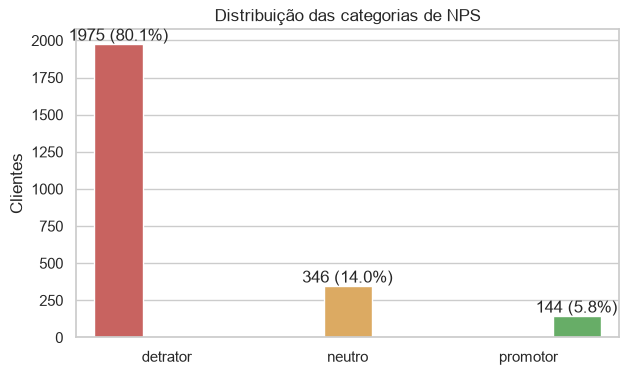

In [3]:
df["nps_categoria"] = pd.cut(
    df["nps_score"],
    bins=[-np.inf, 6.5, 8.5, np.inf],
    labels=["detrator", "neutro", "promotor"],
)
df["detrator"] = (df["nps_categoria"] == "detrator").astype(int)

fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df, x="nps_categoria", hue="nps_categoria", ax=ax, legend=False,
              palette={"detrator": "#d9534f", "neutro": "#f0ad4e", "promotor": "#5cb85c"})
for p in ax.patches:
    ax.annotate(f"{p.get_height():.0f} ({p.get_height() / len(df):.1%})",
                (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax.set_title("Distribuição das categorias de NPS")
ax.set_xlabel("")
ax.set_ylabel("Clientes")
plt.show()

**Leitura:** ~80% da base é detratora, ~14% neutra e ~6% promotora. Isso traz duas consequências:

1. **Desbalanceamento:** um modelo que chama todo mundo de detrator já acerta ~80%. Por isso a acurácia não é a métrica principal, e o ponto de corte do modelo é ajustado para equilibrar as duas classes (seções 5 e 6).
2. **Possível viés de seleção:** clientes insatisfeitos tendem a responder mais à pesquisa. A base retrata quem respondeu, não a carteira inteira. Isso não se resolve dentro desta base e fica registrado como limitação (seção 7).

## 3. Variáveis de entrada

### Seleção

Critério: estar disponível **antes da pesquisa** e ter mostrado relação com a nota na EDA (`02-eda-.ipynb`).

| Variável | Spearman com a nota | Leitura de negócio |
|---|---|---|
| `delivery_delay_days` | -0,59 | atraso na entrega, principal alavanca operacional |
| `complaints_count` | -0,49 | reclamações registradas |
| `customer_service_contacts` | -0,33 | volume de contatos com o SAC |
| `resolution_time_days` | -0,19 | tempo para resolver o problema |

Correlações de Spearman calculadas no `02-eda-.ipynb` (seções 4 e 5).

**Ficaram de fora:**
- `repeat_purchase_30d`: acontece depois da compra e praticamente entrega a resposta ao modelo (vazamento de dados);
- `csat_internal_score`: não se sabe quando é coletada, então há risco de vazamento;
- variáveis sem relação com a nota (frete, tentativas, prazo, valor do pedido, desconto, parcelas, itens, idade e tempo de relacionamento): no `02-eda-.ipynb` (seção 6), todas ficaram com Spearman entre -0,04 e 0,03. A região também não muda a nota (Kruskal-Wallis, p = 0,47);
- identificadores (`customer_id`, `order_id`).

Nos notebooks auxiliares, o modelo com todas as variáveis candidatas não superou o de 4 variáveis (AUC de 0,888 contra 0,891 na validação cruzada), o que confirma a seleção.

In [4]:
FEATURES = [
    "delivery_delay_days",
    "complaints_count",
    "customer_service_contacts",
    "resolution_time_days",
]
TARGET = "detrator"

X = df[FEATURES]
y = df[TARGET]

pd.DataFrame({
    "nulos": X.isna().sum(),
    "mínimo": X.min(),
    "mediana": X.median(),
    "máximo": X.max(),
})

,nulos,mínimo,mediana,máximo
delivery_delay_days,0,0,2.0,8
complaints_count,0,0,4.0,11
customer_service_contacts,0,0,1.0,7
resolution_time_days,0,0,6.0,11


### Preparação

- **Sem valores ausentes** e todas numéricas, então não há imputação nem codificação de categorias.
- **Padronização (`StandardScaler`):** as variáveis têm escalas diferentes (dias e quantidades). A padronização deixa os coeficientes da regressão logística comparáveis entre si.
- A padronização fica **dentro do pipeline** do modelo: ela aprende média e desvio só com os dados de treino (de cada fold, na validação cruzada), o que evita vazamento de informação do teste.

## 4. Separação dos dados

- **Base inteira:** pela fórmula de Cochran, ~333 linhas bastariam para estimar proporções, mas o objetivo é treinar um modelo. Cortar dados só tiraria informação, principalmente dos 144 promotores.
- **Treino e teste (80/20):** divisão estratificada pelas **3 categorias de NPS**, e não só pelo alvo binário, para manter neutros e promotores nas duas partes. Semente fixa para reprodutibilidade.
- **Validação cruzada:** 5 folds estratificados, só no treino, para comparar modelos. O teste fica guardado para uma única avaliação final.

In [5]:
X_train, X_test, y_train, y_test, cat_train, cat_test = train_test_split(
    X, y, df["nps_categoria"],
    test_size=0.2,
    stratify=df["nps_categoria"],
    random_state=RANDOM_STATE,
)

print(f"Treino: {len(X_train)} linhas | Teste: {len(X_test)} linhas")
pd.DataFrame({
    "base_completa_%": df["nps_categoria"].value_counts(normalize=True) * 100,
    "treino_%": cat_train.value_counts(normalize=True) * 100,
    "teste_%": cat_test.value_counts(normalize=True) * 100,
}).round(1)

Treino: 1972 linhas | Teste: 493 linhas


,base_completa_%,treino_%,teste_%
nps_categoria,,,
detrator,80.1,80.1,80.1
neutro,14.0,14.0,14.0
promotor,5.8,5.8,5.9


### Treino e teste representam a base?

- **Categorias:** teste qui-quadrado.
- **Variáveis:** teste de Kolmogorov-Smirnov.

p-valor acima de 0,05 indica que não há diferença relevante entre treino e teste.

In [6]:
chi2, p_chi2, _, _ = chi2_contingency(pd.DataFrame({
    "treino": cat_train.value_counts(),
    "teste": cat_test.value_counts(),
}))
print(f"Qui-quadrado (categorias): {chi2:.3f} | p-valor: {p_chi2:.3f}")

ks = pd.DataFrame(
    [(col, *ks_2samp(X_train[col], X_test[col])) for col in FEATURES],
    columns=["variavel", "estatistica_ks", "p_valor"],
).round(3)
ks["representativa"] = np.where(ks["p_valor"] > 0.05, "sim", "não")
ks

Qui-quadrado (categorias): 0.002 | p-valor: 0.999


,variavel,estatistica_ks,p_valor,representativa
0,delivery_delay_days,0.034,0.745,sim
1,complaints_count,0.025,0.965,sim
2,customer_service_contacts,0.052,0.227,sim
3,resolution_time_days,0.035,0.695,sim


## 5. Escolha do modelo

### O que foi testado

Os experimentos estão em `modelos_auxiliares/03-model-01.ipynb` (com pesos por classe) e `modelos_auxiliares/03-model-02.ipynb` (sem pesos). Resumo da validação cruzada no treino, com o corte padrão de 0,5:

| Modelo | Pesos por classe | ROC-AUC | Recall não detrator (corte 0,5) |
|---|---|---|---|
| Dummy (linha de base) | não se aplica | 0,500 | 0,000 |
| Regressão logística | sim | 0,891 | 0,809 |
| Random forest | sim | 0,882 | 0,778 |
| **Regressão logística** | **não** | **0,890** | 0,495 → equilibrado pelo corte (seção 6) |
| Random forest | não | 0,883 | 0,449 |

### Modelo escolhido: regressão logística sem pesos, com corte ajustado

- **Desempenho:** empata com a random forest em AUC. A random forest não capturou nenhuma relação que a logística deixasse de ver.
- **Explicabilidade:** cada coeficiente mostra quanto um fator operacional aumenta o risco, algo que a operação entende e consegue acompanhar.
- **Pesos ou corte?** O AUC é o mesmo com e sem pesos (0,891 contra 0,890): os pesos não melhoram a capacidade de ordenar os clientes por risco, só deslocam o corte. Sem pesos e com corte de 0,5, o modelo reconhece só metade dos satisfeitos; subindo o corte, ele chega ao mesmo equilíbrio da versão com pesos. Ficamos sem pesos por dois motivos:
  1. **Probabilidades legíveis:** sem pesos, a probabilidade prevista acompanha a chance real nesta base. Um cliente com 0,9 tem ~90% de chance de ser detrator (conferido na seção 6). Os pesos distorcem essa leitura.
  2. **Modelo mais simples:** um ajuste a menos no treino. O equilíbrio entre as classes fica explícito no corte, que a operação pode mudar sem retreinar o modelo.
- **O corte é escolhido na validação cruzada do treino** (seção 6), nunca no teste, para que o teste continue sendo uma avaliação independente.

A linha de base (`DummyClassifier`) chuta pela proporção da base, sem olhar as variáveis. Todo modelo útil precisa superá-la.

In [7]:
modelos = {
    "Dummy (linha de base)": DummyClassifier(strategy="prior"),
    "Regressão logística": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    ),
}

## 6. Avaliação dos resultados

### Métricas

| Métrica | Pergunta de negócio |
|---|---|
| **ROC-AUC** | O modelo ordena bem os clientes por risco? (0,5 = sorteio, 1 = perfeito) |
| **Recall detrator** | De todos os detratores, quantos o modelo pega? |
| **Precisão detrator** | Dos alertas, quantos eram mesmo detratores? |
| **Recall não detrator** | Dos satisfeitos, quantos o modelo reconhece? Esse número não pode zerar. |
| **F1 macro** | Equilíbrio entre as duas classes |

### Escolha do corte (validação cruzada no treino)

Cada cliente do treino recebe uma probabilidade calculada por um modelo que não o viu (previsão fora do fold). Testamos cortes de 0,50 a 0,95 e escolhemos aquele em que o recall dos detratores e o dos satisfeitos ficam mais próximos: o modelo não favorece nenhuma das classes. O teste não participa dessa escolha.

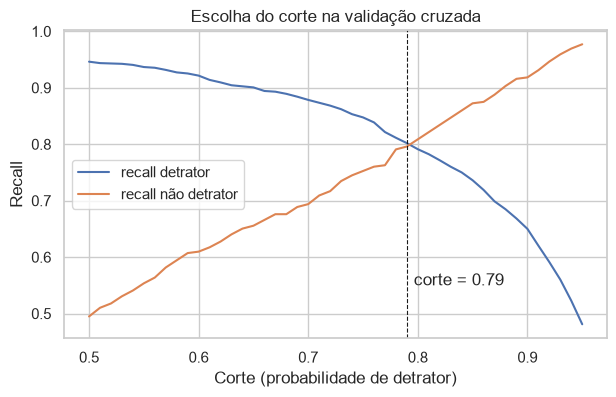

Corte escolhido: 0.79


In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
proba_oof = cross_val_predict(
    modelos["Regressão logística"], X_train, y_train, cv=cv, method="predict_proba",
)[:, 1]

grade = pd.DataFrame({"corte": np.round(np.arange(0.50, 0.96, 0.01), 2)})
grade["recall_detrator"] = [recall_score(y_train, proba_oof >= c, pos_label=1) for c in grade["corte"]]
grade["recall_nao_detrator"] = [recall_score(y_train, proba_oof >= c, pos_label=0) for c in grade["corte"]]
CORTE = float(grade.loc[(grade["recall_detrator"] - grade["recall_nao_detrator"]).abs().idxmin(), "corte"])

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(grade["corte"], grade["recall_detrator"], label="recall detrator")
ax.plot(grade["corte"], grade["recall_nao_detrator"], label="recall não detrator")
ax.axvline(CORTE, color="k", ls="--", lw=0.8)
ax.annotate(f"corte = {CORTE:.2f}", (CORTE, 0.55), xytext=(5, 0), textcoords="offset points")
ax.set_xlabel("Corte (probabilidade de detrator)")
ax.set_ylabel("Recall")
ax.set_title("Escolha do corte na validação cruzada")
ax.legend()
plt.show()
print(f"Corte escolhido: {CORTE:.2f}")

### Validação cruzada (treino)

Métricas por fold com o corte escolhido (`FixedThresholdClassifier`). Como o corte saiu desses mesmos folds, os números são levemente otimistas; a avaliação independente é o teste.

In [9]:
modelos_cv = {
    "Dummy (linha de base)": modelos["Dummy (linha de base)"],
    "Regressão logística": FixedThresholdClassifier(
        modelos["Regressão logística"], threshold=CORTE, response_method="predict_proba",
    ),
}
SCORING = {
    "roc_auc": "roc_auc",
    "recall_detrator": make_scorer(recall_score, pos_label=1),
    "precisao_detrator": make_scorer(precision_score, pos_label=1, zero_division=0),
    "recall_nao_detrator": make_scorer(recall_score, pos_label=0),
    "f1_macro": "f1_macro",
}

resultados_cv = {}
for nome, modelo in modelos_cv.items():
    scores = cross_validate(modelo, X_train, y_train, cv=cv, scoring=SCORING)
    resultados_cv[nome] = {
        metrica: f"{scores[f'test_{metrica}'].mean():.3f} ± {scores[f'test_{metrica}'].std():.3f}"
        for metrica in SCORING
    }
pd.DataFrame(resultados_cv).T

,roc_auc,recall_detrator,precisao_detrator,recall_nao_detrator,f1_macro
Dummy (linha de base),0.500 ± 0.000,1.000 ± 0.000,0.801 ± 0.001,0.000 ± 0.000,0.445 ± 0.000
Regressão logística,0.890 ± 0.005,0.802 ± 0.014,0.941 ± 0.008,0.796 ± 0.032,0.740 ± 0.009


### Avaliação final no teste

Modelo treinado com todo o treino e avaliado uma única vez no teste, que mantém a proporção real (~80% de detratores). A regressão logística usa o corte escolhido acima; a linha de base, o corte de 0,5.

In [10]:
CORTES = {"Dummy (linha de base)": 0.5, "Regressão logística": CORTE}

probas, predicoes, metricas_teste = {}, {}, {}
for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    probas[nome] = modelo.predict_proba(X_test)[:, 1]
    predicoes[nome] = (probas[nome] >= CORTES[nome]).astype(int)
    metricas_teste[nome] = {
        "roc_auc": roc_auc_score(y_test, probas[nome]),
        "recall_detrator": recall_score(y_test, predicoes[nome], pos_label=1),
        "precisao_detrator": precision_score(y_test, predicoes[nome], pos_label=1, zero_division=0),
        "recall_nao_detrator": recall_score(y_test, predicoes[nome], pos_label=0),
        "f1_macro": f1_score(y_test, predicoes[nome], average="macro"),
    }
pd.DataFrame(metricas_teste).T.round(3)

,roc_auc,recall_detrator,precisao_detrator,recall_nao_detrator,f1_macro
Dummy (linha de base),0.50,1.000,0.801,0.000,0.445
Regressão logística,0.88,0.815,0.936,0.776,0.743


### Matriz de confusão

Linhas mostram a classe real e colunas, a classe prevista. A classe positiva é **detrator**.

| | Previsto: não detrator | Previsto: detrator |
|---|---|---|
| **Real: não detrator** | VN (verdadeiro negativo): satisfeito reconhecido | **FP (falso positivo):** satisfeito abordado sem necessidade |
| **Real: detrator** | **FN (falso negativo):** detrator que passou batido | VP (verdadeiro positivo): detrator identificado |

O FN é o erro mais caro, porque o cliente insatisfeito fica sem nenhuma ação. O FP gasta esforço da equipe com quem já estava satisfeito.

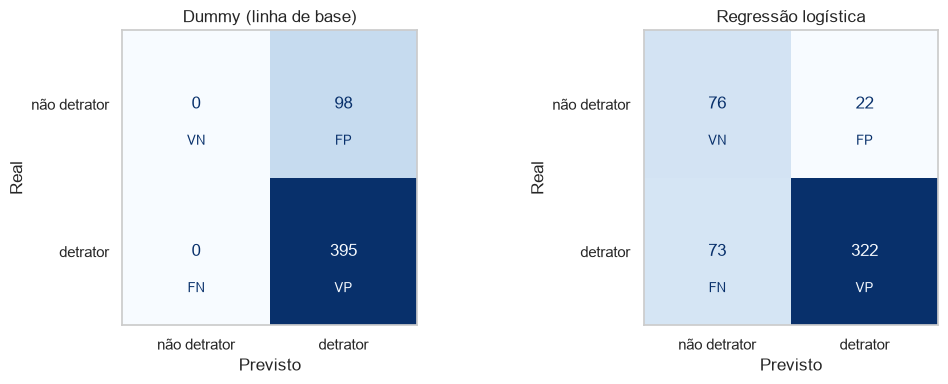

Regressão logística: 73 de 395 detratores passaram batido (FN) e 22 de 98 satisfeitos seriam abordados sem necessidade (FP).


In [11]:
ROTULOS = np.array([["VN", "FP"], ["FN", "VP"]])

fig, axes = plt.subplots(1, len(modelos), figsize=(11, 4))
for ax, nome in zip(axes, modelos):
    disp = ConfusionMatrixDisplay(
        confusion_matrix(y_test, predicoes[nome]),
        display_labels=["não detrator", "detrator"],
    ).plot(ax=ax, cmap="Blues", colorbar=False)
    for (i, j), rotulo in np.ndenumerate(ROTULOS):
        ax.text(j, i + 0.25, rotulo, ha="center", va="center", fontsize=9,
                color=disp.text_[i, j].get_color())
    ax.grid(False)
    ax.set_xlabel("Previsto")
    ax.set_ylabel("Real")
    ax.set_title(nome)
plt.tight_layout()
plt.show()

vn, fp, fn, vp = confusion_matrix(y_test, predicoes["Regressão logística"]).ravel()
print(f"Regressão logística: {fn} de {fn + vp} detratores passaram batido (FN) "
      f"e {fp} de {fp + vn} satisfeitos seriam abordados sem necessidade (FP).")

### Curva ROC

Quanto mais longe da diagonal, melhor o modelo separa clientes de alto e de baixo risco.

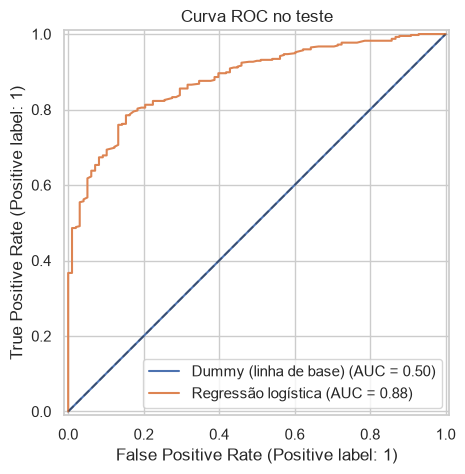

In [12]:
fig, ax = plt.subplots(figsize=(6, 5))
for nome in modelos:
    RocCurveDisplay.from_predictions(y_test, probas[nome], name=nome, ax=ax)
ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
ax.set_title("Curva ROC no teste")
plt.show()

### As probabilidades são confiáveis?

Sem pesos por classe, a probabilidade prevista deve acompanhar a taxa real de detratores. A tabela agrupa os clientes do teste por faixa de probabilidade e compara a média prevista com a taxa observada.

In [13]:
calibracao = (
    pd.DataFrame({
        "faixa": pd.cut(probas["Regressão logística"], bins=[0, 0.5, 0.7, 0.8, 0.9, 1]),
        "proba": probas["Regressão logística"],
        "detrator": y_test.values,
    })
    .groupby("faixa", observed=True)
    .agg(clientes=("detrator", "size"), proba_media=("proba", "mean"), taxa_real=("detrator", "mean"))
    .round(3)
)
calibracao

,clientes,proba_media,taxa_real
faixa,,,
"(0.0, 0.5]",64,0.319,0.344
"(0.5, 0.7]",47,0.595,0.574
"(0.7, 0.8]",43,0.754,0.628
"(0.8, 0.9]",76,0.858,0.829
"(0.9, 1.0]",263,0.968,0.973


### Quais fatores pesam na satisfação?

Coeficiente positivo aumenta o risco de detrator. A razão de chances (*odds ratio*) mostra quanto esse risco se multiplica a cada desvio padrão a mais na variável. A coluna `1_desvio_padrao` traduz esse desvio para a unidade original: dias, no atraso e no tempo de resolução; quantidade, nas reclamações e nos contatos.

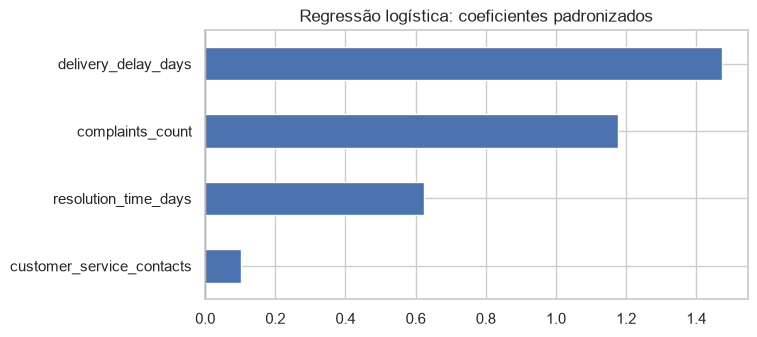

,coeficiente,razao_de_chances,1_desvio_padrao
delivery_delay_days,1.473,4.363,1.448
complaints_count,1.177,3.246,1.769
resolution_time_days,0.623,1.865,3.445
customer_service_contacts,0.101,1.106,1.230


In [14]:
modelo_final = modelos["Regressão logística"]
logreg = modelo_final.named_steps["logisticregression"]
escala = modelo_final.named_steps["standardscaler"]

interpretacao = pd.DataFrame({
    "coeficiente": logreg.coef_[0],
    "razao_de_chances": np.exp(logreg.coef_[0]),
    "1_desvio_padrao": escala.scale_,
}, index=FEATURES).sort_values("coeficiente", ascending=False).round(3)

fig, ax = plt.subplots(figsize=(7, 3.5))
interpretacao["coeficiente"].sort_values().plot.barh(ax=ax, color="#4c72b0")
ax.axvline(0, color="k", lw=0.8)
ax.set_title("Regressão logística: coeficientes padronizados")
plt.show()
interpretacao

### Ponto de corte

O corte escolhido na validação cruzada é o ponto de partida. O valor final deve ser definido com a operação, de acordo com quantos clientes a equipe consegue abordar: corte alto gera menos alertas e mais certeiros; corte baixo gera mais alertas e cobre mais detratores. Como o corte é aplicado depois do modelo, mudá-lo não exige retreino.

In [15]:
proba_final = probas["Regressão logística"]
cortes = []
for corte in sorted({0.5, 0.6, 0.7, 0.75, CORTE, 0.85, 0.9}):
    pred = (proba_final >= corte).astype(int)
    cortes.append({
        "corte": round(corte, 2),
        "clientes_alertados_%": round(pred.mean() * 100, 1),
        "recall_detrator": recall_score(y_test, pred, pos_label=1),
        "precisao_detrator": precision_score(y_test, pred, pos_label=1, zero_division=0),
        "recall_nao_detrator": recall_score(y_test, pred, pos_label=0),
    })
pd.DataFrame(cortes).round(3)

,corte,clientes_alertados_%,recall_detrator,precisao_detrator,recall_nao_detrator
0,0.50,87.0,0.944,0.869,0.429
1,0.60,82.2,0.914,0.891,0.551
2,0.70,77.5,0.876,0.906,0.633
3,0.75,74.2,0.853,0.921,0.704
4,0.79,69.8,0.815,0.936,0.776
5,0.85,61.7,0.737,0.957,0.867
6,0.90,53.3,0.648,0.973,0.929


### Priorização por ranking de risco

Alternativa ao corte: ordenar os clientes por risco e atuar nos X% do topo. O *lift* compara a taxa de detratores de cada faixa com a média do teste.

In [16]:
ranking = pd.DataFrame({"proba": proba_final, "detrator": y_test.values}).sort_values("proba", ascending=False)
taxa_geral = ranking["detrator"].mean()
faixas = []
for top in [0.1, 0.2, 0.3, 0.5]:
    grupo = ranking.head(int(len(ranking) * top))
    faixas.append({
        "top_%_de_risco": int(top * 100),
        "clientes": len(grupo),
        "taxa_detratores_%": round(grupo["detrator"].mean() * 100, 1),
        "lift": round(grupo["detrator"].mean() / taxa_geral, 2),
    })
print(f"Taxa geral de detratores no teste: {taxa_geral:.1%}")
pd.DataFrame(faixas)

Taxa geral de detratores no teste: 80.1%


,top_%_de_risco,clientes,taxa_detratores_%,lift
0,10,49,100.0,1.25
1,20,98,100.0,1.25
2,30,147,99.3,1.24
3,50,246,98.0,1.22


### Leitura da avaliação

- **AUC de ~0,88 no teste**, contra 0,50 da linha de base. Validação cruzada (~0,89) e teste batem, sem sinal de sobreajuste.
- **No corte de 0,79:** pega ~81% dos detratores com ~94% de precisão e reconhece ~78% dos satisfeitos. Em números: 73 de 395 detratores passam batido (FN) e 22 de 98 satisfeitos seriam abordados sem necessidade (FP). A linha de base reconhece 0% dos satisfeitos.
- **Probabilidades calibradas:** em cada faixa, a probabilidade média prevista fica perto da taxa real de detratores (ex.: acima de 0,9, prevista de 0,97 e real de 0,97). A operação pode ler a probabilidade como chance.
- **Ranking:** os 20% de maior risco são 100% detratores. O *lift* (~1,25) parece baixo só porque a base já tem ~80% de detratores; o teto possível seria 1,25.
- **Fatores**, por desvio padrão a mais em cada variável:
  1. **Atraso na entrega:** cada ~1,4 dia a mais multiplica por ~4,4 a chance de o cliente ser detrator.
  2. **Reclamações:** cada ~1,8 reclamação a mais multiplica a chance por ~3,2.
  3. **Tempo de resolução:** cada ~3,4 dias a mais multiplica a chance por ~1,9.
  4. **Contatos com o SAC:** efeito pequeno (~1,1) quando os outros fatores já estão no modelo. A informação provavelmente já vem das reclamações.

## 7. Como a empresa usaria o modelo

**1. Quando o modelo roda**

As quatro variáveis do modelo já existem nos sistemas antes da pesquisa: atraso na entrega, reclamações, contatos com o SAC e tempo de resolução. A proposta é recalcular o risco de cada pedido uma vez por dia, ou a cada novo evento (entrega atrasada, reclamação aberta), no intervalo entre a entrega e o envio da pesquisa de NPS.

**2. Onde o resultado aparece**

O `src/train_model.py` treina este mesmo modelo com a base completa e salva o artefato em `models/baseline_regressao_logistica.joblib`, com o corte de 0,79 e as demais informações nos metadados (`.json`). A API (`api.py`) hoje expõe os dados, os indicadores e as informações do modelo (`GET /modelo`). O próximo passo é um endpoint de pontuação que receba as quatro variáveis e devolva a probabilidade de detrator, para alimentar uma fila diária no CRM ou no painel do SAC, ordenada do maior para o menor risco.

**3. Quem é abordado**

A regra de corte depende de quantos clientes a equipe consegue atender. Números do teste:

| Cenário | Regra | Efeito no teste |
|---|---|---|
| Equipe enxuta | top 20% do ranking de risco | 100% dos abordados são detratores |
| Equilíbrio (padrão) | probabilidade ≥ 0,79 | 70% dos clientes alertados; pega 81% dos detratores; 22% dos satisfeitos abordados sem necessidade |
| Mais precisão | probabilidade ≥ 0,90 | 53% dos clientes alertados; 97% dos alertas são detratores |
| Cobertura máxima | probabilidade ≥ 0,50 | 87% dos clientes alertados; pega 94% dos detratores |

Como ~80% da base é detratora, mesmo o cenário padrão alerta a maior parte dos clientes. Por isso, o ranking tende a ser mais útil que o corte: a equipe começa pelo topo e desce até onde a capacidade permitir.

**4. O que fazer com cada alerta**

O modelo dá a probabilidade, e o motivo do alerta aparece nas próprias variáveis do cliente:

| Fator de risco | Ação sugerida | Área |
|---|---|---|
| Atraso na entrega | avisar o cliente antes, informar nova previsão, oferecer cupom ou frete grátis na próxima compra | Logística e CRM |
| Reclamações | escalonar para atendimento prioritário e fazer contato ativo | SAC |
| Tempo de resolução alto | cobrar o prazo do chamado e acompanhar até o fechamento | SAC |
| Muitos contatos com o SAC | priorizar a resolução no primeiro contato | SAC |

**5. Como medir se funcionou**

Depois da pesquisa, comparar a taxa de detratores e o NPS entre os grupos abordado e de controle.

**6. Cuidados**
- **Viés de seleção:** o modelo aprendeu com quem respondeu à pesquisa (~80% de detratores). Na carteira inteira os satisfeitos devem ser mais numerosos, então as probabilidades tendem a ficar superestimadas. A ordem do ranking continua útil, mas a probabilidade deve ser recalibrada quando houver dados da carteira completa.
- **Associação não é causa:** o modelo mostra que atraso e reclamações acompanham notas baixas. O efeito real das ações só se confirma com o grupo de controle.
- **Monitoramento:** acompanhar todo mês o AUC e a taxa de detratores entre os alertados, e retreinar com `src/train_model.py` quando o desempenho cair ou a operação mudar (nova transportadora, nova política de SAC).

## Conclusão

| Pergunta | Resposta |
|---|---|
| **Variável alvo** | `detrator` (nota ≤ 6,5), binária. ~80% da base. |
| **Variáveis de entrada** | 4 variáveis operacionais disponíveis antes da pesquisa: atraso, reclamações, contatos com o SAC e tempo de resolução. Padronizadas dentro do pipeline. Sem variáveis com risco de vazamento. |
| **Separação dos dados** | Base inteira; 80/20 estratificado pelas 3 categorias de NPS, com representatividade confirmada (qui-quadrado e KS); validação cruzada de 5 folds no treino. |
| **Modelo** | Regressão logística sem pesos, com corte de 0,79 escolhido na validação cruzada: empata com a random forest, é explicável e dá probabilidades que acompanham a chance real. |
| **Avaliação** | AUC de ~0,88 no teste (0,50 na linha de base); no corte de 0,79, pega ~81% dos detratores com ~94% de precisão e reconhece ~78% dos satisfeitos. |
| **Uso prático** | Ranking diário de risco para o SAC e a logística agirem antes da pesquisa, começando pelo atraso na entrega, com grupo de controle para medir o efeito. |